In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import os

os.chdir('/Users/liujingxin/Documents/Quant_Project')

matplotlib.rcParams['font.family'] = 'Arial Unicode MS'
matplotlib.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('data/factor_data.csv', parse_dates=['trade_date'])

print(f'数据读取成功：{len(df):,} 行')
df.head()

数据读取成功：256,461 行


,ts_code,trade_date,industry,total_mv,EP,BP,EP_neutralized,BP_neutralized,EP_final,BP_final,forward_return
0,000001.SZ,2020-01-23,银行,3.015680e+07,0.093495,0.905387,-1.178178,-0.865714,-1.696011,-0.542067,-0.066924
1,000001.SZ,2020-02-28,银行,2.813858e+07,0.100200,0.970309,-1.089199,-0.803693,-1.549154,-0.420904,-0.117241
2,000001.SZ,2020-03-31,银行,2.483958e+07,0.113509,1.099143,-0.995878,-0.654201,-1.554694,-0.369827,0.088281
3,000001.SZ,2020-04-30,银行,2.703244e+07,0.108378,1.044714,-1.140160,-0.934224,-1.621241,-0.601894,-0.050691
4,000001.SZ,2020-05-29,银行,2.522769e+07,0.116131,1.300898,-1.013357,-0.142142,-1.447894,0.192428,-0.015385


In [55]:
def calc_monthly_ic(group, factor_col, return_col='forward_return'):
    valid = group[[factor_col, return_col]].dropna()
    if len(valid) < 30:
        return np.nan
    return valid[factor_col].corr(valid[return_col], method='spearman')

ic_ep_raw = df.groupby('trade_date')[['EP', 'forward_return']].apply(
    lambda g: calc_monthly_ic(g, 'EP'), include_groups=False
)
ic_bp_raw = df.groupby('trade_date')[['BP', 'forward_return']].apply(
    lambda g: calc_monthly_ic(g, 'BP'), include_groups=False
)
ic_ep_neu = df.groupby('trade_date')[['EP_final', 'forward_return']].apply(
    lambda g: calc_monthly_ic(g, 'EP_final'), include_groups=False
)
ic_bp_neu = df.groupby('trade_date')[['BP_final', 'forward_return']].apply(
    lambda g: calc_monthly_ic(g, 'BP_final'), include_groups=False
)

ic_df = pd.DataFrame({
    'IC_EP_raw': ic_ep_raw,
    'IC_BP_raw': ic_bp_raw,
    'IC_EP_neu': ic_ep_neu,
    'IC_BP_neu': ic_bp_neu,
}).dropna()

for col, label in [
    ('IC_EP_raw', 'EP 原始'),
    ('IC_BP_raw', 'BP 原始'),
    ('IC_EP_neu', 'EP 中性化'),
    ('IC_BP_neu', 'BP 中性化'),
]:
    print(f'{"="*45}')
    print(f'{label} 因子 IC（1个月）')
    print(f'{"="*45}')
    print(f'IC 均值：  {ic_df[col].mean():.4f}')
    print(f'IC 标准差：{ic_df[col].std():.4f}')
    print(f'ICIR：     {ic_df[col].mean() / ic_df[col].std():.4f}')
    print(f'IC>0 比例：{(ic_df[col] > 0).mean():.1%}')
    print()

EP 原始 因子 IC（1个月）
IC 均值：  0.0379
IC 标准差：0.1552
ICIR：     0.2443
IC>0 比例：60.6%

BP 原始 因子 IC（1个月）
IC 均值：  0.0670
IC 标准差：0.1816
ICIR：     0.3688
IC>0 比例：62.0%

EP 中性化 因子 IC（1个月）
IC 均值：  0.0395
IC 标准差：0.0825
ICIR：     0.4785
IC>0 比例：70.4%

BP 中性化 因子 IC（1个月）
IC 均值：  0.0531
IC 标准差：0.0930
ICIR：     0.5711
IC>0 比例：64.8%



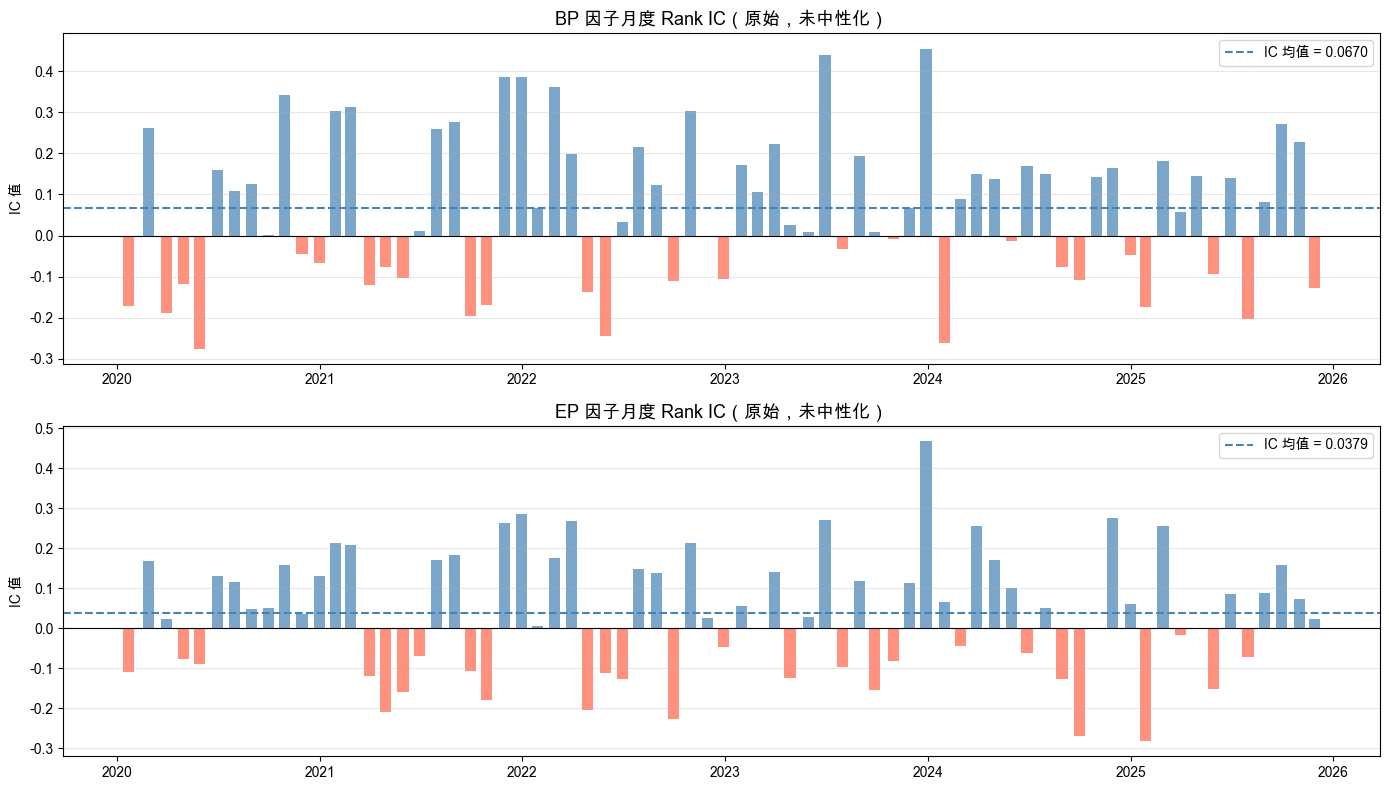

图表已保存到 data/ic_timeseries.png ✓


In [56]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].bar(ic_df.index, ic_df['IC_BP_raw'],
            color=['steelblue' if x > 0 else 'tomato' for x in ic_df['IC_BP_raw']],
            alpha=0.7, width=20)
axes[0].axhline(y=0, color='black', linewidth=0.8)
axes[0].axhline(y=ic_df['IC_BP_raw'].mean(), color='steelblue',
                linewidth=1.5, linestyle='--',
                label=f'IC 均值 = {ic_df["IC_BP_raw"].mean():.4f}')
axes[0].set_title('BP 因子月度 Rank IC（原始，未中性化）', fontsize=13)
axes[0].set_ylabel('IC 值')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(ic_df.index, ic_df['IC_EP_raw'],
            color=['steelblue' if x > 0 else 'tomato' for x in ic_df['IC_EP_raw']],
            alpha=0.7, width=20)
axes[1].axhline(y=0, color='black', linewidth=0.8)
axes[1].axhline(y=ic_df['IC_EP_raw'].mean(), color='steelblue',
                linewidth=1.5, linestyle='--',
                label=f'IC 均值 = {ic_df["IC_EP_raw"].mean():.4f}')
axes[1].set_title('EP 因子月度 Rank IC（原始，未中性化）', fontsize=13)
axes[1].set_ylabel('IC 值')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('data/ic_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()
print('图表已保存到 data/ic_timeseries.png ✓')

In [57]:
def assign_quintile(series):
    result = series.copy() * np.nan
    valid_idx = series.dropna().index
    if len(valid_idx) < 50:
        return result
    result.loc[valid_idx] = pd.qcut(
        series.loc[valid_idx],
        q=5,
        labels=[1, 2, 3, 4, 5],
        duplicates='drop'
    ).astype(float)
    return result

df['BP_quintile'] = (
    df.groupby('trade_date')['BP']
    .transform(lambda x: assign_quintile(x))
)

df['EP_quintile'] = (
    df.groupby('trade_date')['EP']
    .transform(lambda x: assign_quintile(x))
)

bp_quintile_returns = (
    df.groupby(['trade_date', 'BP_quintile'])['forward_return'].mean()
)
ep_quintile_returns = (
    df.groupby(['trade_date', 'EP_quintile'])['forward_return'].mean()
)

bp_mean = bp_quintile_returns.groupby('BP_quintile').mean()
ep_mean = ep_quintile_returns.groupby('EP_quintile').mean()

print('BP 原始因子各组平均月度收益率：')
for q, r in bp_mean.items():
    print(f'  Q{int(q)}：{r:.2%}')

print()
print('EP 原始因子各组平均月度收益率：')
for q, r in ep_mean.items():
    print(f'  Q{int(q)}：{r:.2%}')

BP 原始因子各组平均月度收益率：
  Q1：0.59%
  Q2：1.14%
  Q3：1.40%
  Q4：1.56%
  Q5：1.47%

EP 原始因子各组平均月度收益率：
  Q1：0.95%
  Q2：1.16%
  Q3：1.34%
  Q4：1.51%
  Q5：1.21%


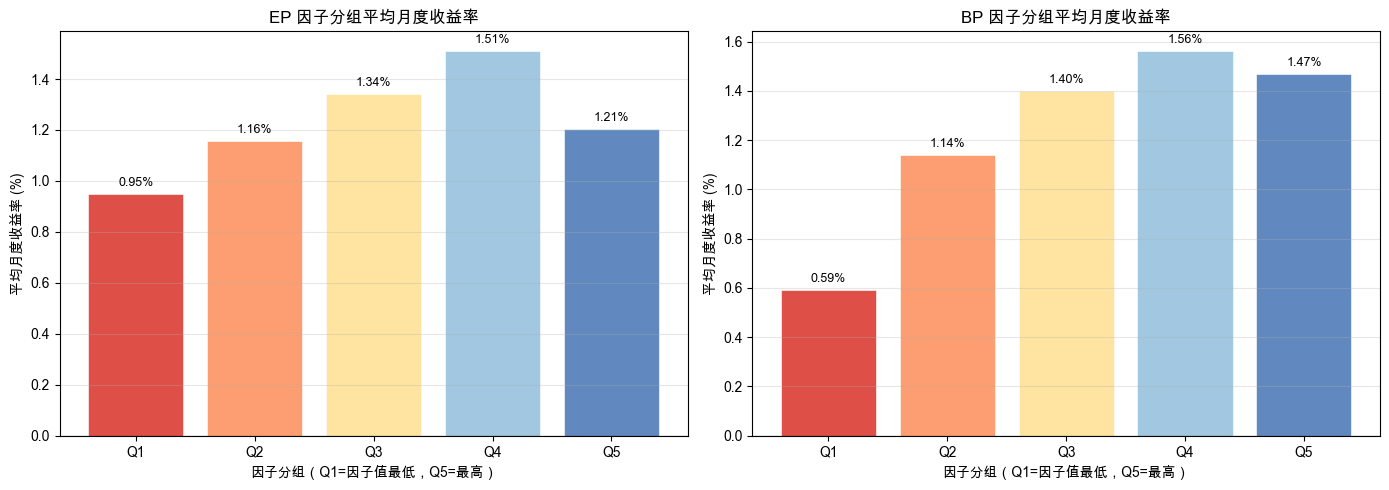

图表已保存到 data/quintile_returns.png ✓


In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars1 = axes[0].bar(
    [f'Q{int(q)}' for q in ep_mean.index],
    ep_mean.values * 100,
    color=['#d73027', '#fc8d59', '#fee090', '#91bfdb', '#4575b4'],
    alpha=0.85, edgecolor='white', linewidth=0.5
)
axes[0].set_title('EP 因子分组平均月度收益率', fontsize=12)
axes[0].set_ylabel('平均月度收益率 (%)')
axes[0].set_xlabel('因子分组（Q1=因子值最低，Q5=最高）')
axes[0].axhline(y=0, color='black', linewidth=0.8)
axes[0].grid(axis='y', alpha=0.3)
for bar, val in zip(bars1, ep_mean.values * 100):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{val:.2f}%', ha='center', va='bottom', fontsize=9)

bars2 = axes[1].bar(
    [f'Q{int(q)}' for q in bp_mean.index],
    bp_mean.values * 100,
    color=['#d73027', '#fc8d59', '#fee090', '#91bfdb', '#4575b4'],
    alpha=0.85, edgecolor='white', linewidth=0.5
)
axes[1].set_title('BP 因子分组平均月度收益率', fontsize=12)
axes[1].set_ylabel('平均月度收益率 (%)')
axes[1].set_xlabel('因子分组（Q1=因子值最低，Q5=最高）')
axes[1].axhline(y=0, color='black', linewidth=0.8)
axes[1].grid(axis='y', alpha=0.3)
for bar, val in zip(bars2, bp_mean.values * 100):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{val:.2f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('data/quintile_returns.png', dpi=150, bbox_inches='tight')
plt.show()
print('图表已保存到 data/quintile_returns.png ✓')

In [59]:
bp_pivot = bp_quintile_returns.unstack('BP_quintile')
ep_pivot = ep_quintile_returns.unstack('EP_quintile')
bp_ls = bp_pivot[5.0] - bp_pivot[1.0]
ep_ls = ep_pivot[5.0] - ep_pivot[1.0]
bp_nav = (1 + bp_ls).cumprod()
ep_nav = (1 + ep_ls).cumprod()
market_return = df.groupby('trade_date')['forward_return'].mean()
market_nav = (1 + market_return).cumprod()

def calc_performance(returns):
    annual_return = returns.mean() * 12
    annual_vol = returns.std() * np.sqrt(12)
    sharpe = annual_return / annual_vol
    nav = (1 + returns).cumprod()
    rolling_max = nav.cummax()
    drawdown = (nav - rolling_max) / rolling_max
    max_drawdown = drawdown.min()
    return annual_return, annual_vol, sharpe, max_drawdown

bp_stats = calc_performance(bp_ls.dropna())
ep_stats = calc_performance(ep_ls.dropna())

print('=' * 55)
print(f'{"指标":<15} {"BP 多空组合":>15} {"EP 多空组合":>15}')
print('=' * 55)
print(f'{"年化收益率":<15} {bp_stats[0]:>14.2%} {ep_stats[0]:>14.2%}')
print(f'{"年化波动率":<15} {bp_stats[1]:>14.2%} {ep_stats[1]:>14.2%}')
print(f'{"夏普比率":<15} {bp_stats[2]:>14.4f} {ep_stats[2]:>14.4f}')
print(f'{"最大回撤":<15} {bp_stats[3]:>14.2%} {ep_stats[3]:>14.2%}')
print('=' * 55)

指标                      BP 多空组合         EP 多空组合
年化收益率                   10.53%          3.08%
年化波动率                   18.93%         15.98%
夏普比率                    0.5560         0.1928
最大回撤                   -18.13%        -22.49%


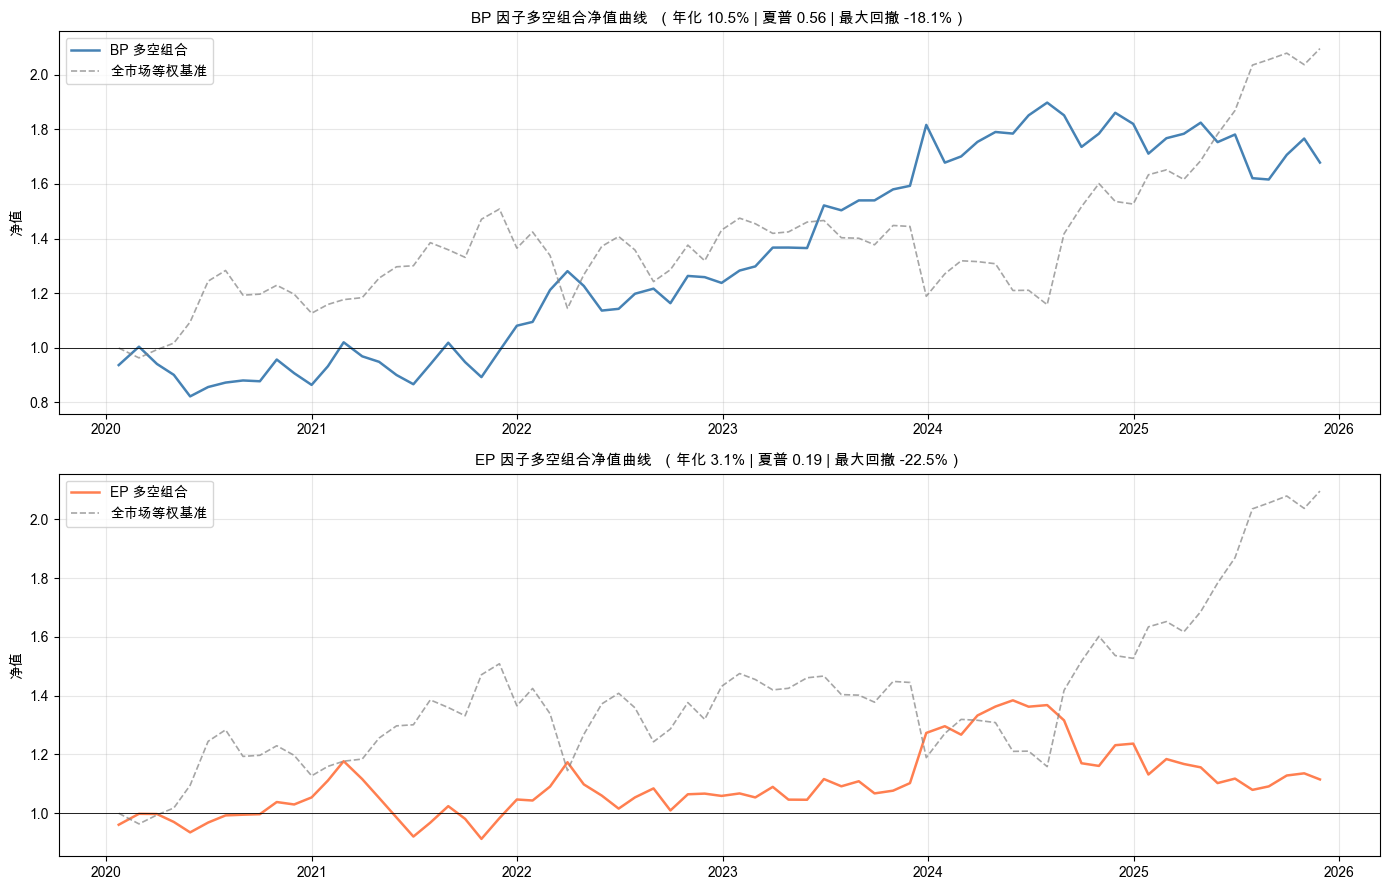

图表已保存 ✓


In [60]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(bp_nav.index, bp_nav.values,
             color='steelblue', linewidth=1.8, label='BP 多空组合')
axes[0].plot(market_nav.index, market_nav.values,
             color='gray', linewidth=1.2, linestyle='--',
             alpha=0.7, label='全市场等权基准')
axes[0].axhline(y=1, color='black', linewidth=0.6)
axes[0].set_title(
    f'BP 因子多空组合净值曲线  '
    f'（年化 {bp_stats[0]:.1%} | 夏普 {bp_stats[2]:.2f} | 最大回撤 {bp_stats[3]:.1%}）',
    fontsize=11)
axes[0].set_ylabel('净值')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(ep_nav.index, ep_nav.values,
             color='coral', linewidth=1.8, label='EP 多空组合')
axes[1].plot(market_nav.index, market_nav.values,
             color='gray', linewidth=1.2, linestyle='--',
             alpha=0.7, label='全市场等权基准')
axes[1].axhline(y=1, color='black', linewidth=0.6)
axes[1].set_title(
    f'EP 因子多空组合净值曲线  '
    f'（年化 {ep_stats[0]:.1%} | 夏普 {ep_stats[2]:.2f} | 最大回撤 {ep_stats[3]:.1%}）',
    fontsize=11)
axes[1].set_ylabel('净值')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('data/nav_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('图表已保存 ✓')

In [61]:
# 1) 确认 BP 中性化 IC
print(ic_df[['IC_EP_neu', 'IC_BP_neu']].agg(['mean', 'std']).round(4))

# 2) 用中性化因子重做分组（沿用 transform 写法，避免错位）
df['BP_neu_q'] = df.groupby('trade_date')['BP_final'].transform(assign_quintile)
df['EP_neu_q'] = df.groupby('trade_date')['EP_final'].transform(assign_quintile)

bp_neu_ret = df.groupby(['trade_date', 'BP_neu_q'])['forward_return'].mean()
ep_neu_ret = df.groupby(['trade_date', 'EP_neu_q'])['forward_return'].mean()

print('\nBP 中性化各组平均月度收益：')
print((bp_neu_ret.groupby('BP_neu_q').mean() * 100).round(2).to_string())
print('\nEP 中性化各组平均月度收益：')
print((ep_neu_ret.groupby('EP_neu_q').mean() * 100).round(2).to_string())

# 3) 多空组合绩效，与原始版本对比
bp_neu_ls = bp_neu_ret.unstack()[5.0] - bp_neu_ret.unstack()[1.0]
ep_neu_ls = ep_neu_ret.unstack()[5.0] - ep_neu_ret.unstack()[1.0]

print('\n指标            BP原始    BP中性化   EP原始    EP中性化')
for name, i in [('年化收益', 0), ('年化波动', 1), ('夏普', 2), ('最大回撤', 3)]:
    vals = [bp_stats[i], calc_performance(bp_neu_ls.dropna())[i],
            ep_stats[i], calc_performance(ep_neu_ls.dropna())[i]]
    print(f'{name:<8}' + ''.join(f'{v:>10.3f}' for v in vals))

      IC_EP_neu  IC_BP_neu
mean     0.0395     0.0531
std      0.0825     0.0930

BP 中性化各组平均月度收益：
BP_neu_q
1.0    0.80
2.0    1.06
3.0    1.23
4.0    1.49
5.0    1.58

EP 中性化各组平均月度收益：
EP_neu_q
1.0    0.85
2.0    1.12
3.0    1.15
4.0    1.44
5.0    1.59

指标            BP原始    BP中性化   EP原始    EP中性化
年化收益         0.105     0.094     0.031     0.088
年化波动         0.189     0.098     0.160     0.086
夏普           0.556     0.961     0.193     1.029
最大回撤        -0.181    -0.102    -0.225    -0.125


In [62]:
# 1) BP 中性化多空组合，按年份拆开
yearly = bp_neu_ls.groupby(bp_neu_ls.index.year).agg(['mean', 'std', 'count'])
yearly['年化收益'] = yearly['mean'] * 12
print(yearly[['年化收益', 'count']].round(3))

             年化收益  count
trade_date              
2020       -0.029     12
2021        0.174     12
2022        0.083     12
2023        0.269     12
2024        0.059     12
2025       -0.000     11


In [63]:
# 只做多 Q5（中性化 BP），对比全市场等权
long = df[df['BP_neu_q'] == 5.0]
long_ret = long.groupby('trade_date')['forward_return'].mean()
mkt_ret = df.groupby('trade_date')['forward_return'].mean()

# 月度换手率：本月 Q5 里有多少比例是上月不在 Q5 的股票
members = long.groupby('trade_date')['ts_code'].apply(set)
turnover = pd.Series(1.0, index=members.index)   # 第一个月视为全部新买入
for i in range(1, len(members)):
    prev, cur = members.iloc[i-1], members.iloc[i]
    turnover.iloc[i] = 1 - len(prev & cur) / len(cur)

ROUND_TRIP = 0.003    # 一买一卖合计 0.3%（假设值，可改成 0.002 / 0.004 看敏感性）
long_net = long_ret - turnover * ROUND_TRIP

excess_gross = long_ret - mkt_ret
excess_net = long_net - mkt_ret

print(f'平均月换手率：{turnover.iloc[1:].mean():.1%}')
print('\n指标          只做多(税前) 只做多(税后) 全市场   超额(税前) 超额(税后)')
for name, i in [('年化收益', 0), ('年化波动', 1), ('夏普/IR', 2), ('最大回撤', 3)]:
    vals = [calc_performance(long_ret)[i], calc_performance(long_net)[i],
            calc_performance(mkt_ret)[i], calc_performance(excess_gross)[i],
            calc_performance(excess_net)[i]]
    print(f'{name:<10}' + ''.join(f'{v:>12.3f}' for v in vals))

平均月换手率：10.5%

指标          只做多(税前) 只做多(税后) 全市场   超额(税前) 超额(税后)
年化收益             0.190       0.186       0.148       0.042       0.038
年化波动             0.199       0.199       0.212       0.053       0.054
夏普/IR            0.956       0.934       0.697       0.792       0.711
最大回撤            -0.171      -0.172      -0.241      -0.052      -0.053


In [64]:
def ic_stats(s):
    return [s.mean(), s.std(), s.mean() / s.std(), (s > 0).mean()]

perf = {
    'EP原始':  (ic_df['IC_EP_raw'], ep_stats),
    'BP原始':  (ic_df['IC_BP_raw'], bp_stats),
    'EP中性化': (ic_df['IC_EP_neu'], calc_performance(ep_neu_ls.dropna())),
    'BP中性化': (ic_df['IC_BP_neu'], calc_performance(bp_neu_ls.dropna())),
}
summary = pd.DataFrame({'指标': ['IC均值', 'IC标准差', 'ICIR', 'IC>0比例',
                               '年化收益率', '年化波动率', '夏普比率', '最大回撤']})
for name, (ic, p) in perf.items():
    summary[name] = ic_stats(ic) + list(p)
summary.to_csv('data/results_summary.csv', index=False)
print(summary.round(4).to_string(index=False))

    指标    EP原始    BP原始   EP中性化   BP中性化
  IC均值  0.0379  0.0670  0.0395  0.0531
 IC标准差  0.1552  0.1816  0.0825  0.0930
  ICIR  0.2443  0.3688  0.4785  0.5711
IC>0比例  0.6056  0.6197  0.7042  0.6479
 年化收益率  0.0308  0.1053  0.0885  0.0941
 年化波动率  0.1598  0.1893  0.0860  0.0980
  夏普比率  0.1928  0.5560  1.0295  0.9609
  最大回撤 -0.2249 -0.1813 -0.1246 -0.1017
